# 02 · Thống kê mô tả

Giá, lợi suất log $r_t = \ln(P_t / P_{t-1})$, biến động và thanh khoản của 20 mã (7 ngành) trong khung phân tích chung.
Mã được xếp theo ngành (màu nhãn và vạch phân cách theo ngành); 5 mã gốc (VHM, NVL, STB, VPB, HPG) được đối chiếu với 15 mã mới.

In [1]:
import sys, warnings
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "sql").is_dir() and (p / "src").is_dir())
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import eda_utils as U

U.apply_publication_style()
pd.set_option("display.float_format", "{:,.4f}".format)
con = U.connect()
SYMBOLS = U.SYMBOLS
COL = U.SYMBOL_COLORS

SECTOR, SECTORS, SC = U.SECTOR, U.SECTORS, U.SECTOR_COLORS


def sector_style(ax, labels, axis="both", sep=True, fs=9):
    """Tô màu nhãn trục theo ngành và kẻ vạch phân cách ngành trên heatmap (nhãn theo thứ tự U.SYMBOLS)."""
    ticks = range(len(labels))
    if axis in ("both", "x"):
        ax.set_xticks(ticks, labels, rotation=90, fontsize=fs)
        for t, s in zip(ax.get_xticklabels(), labels): t.set_color(SC[SECTOR[s]])
    if axis in ("both", "y"):
        ax.set_yticks(ticks, labels, fontsize=fs)
        for t, s in zip(ax.get_yticklabels(), labels): t.set_color(SC[SECTOR[s]])
    if sep:
        cuts = [i - 0.5 for i in range(1, len(labels)) if SECTOR[labels[i]] != SECTOR[labels[i - 1]]]
        for c in cuts:
            ax.axhline(c, color="black", lw=0.8); ax.axvline(c, color="black", lw=0.8)


def big_heatmap(ax, matrix, fs_cell=6.5, annotate=True, **kw):
    """Heatmap 20x20: chữ trong ô nhỏ (hoặc bỏ), nhãn tô màu theo ngành, vạch phân cách ngành."""
    im = U.make_heatmap(ax, matrix, **kw)
    for t in list(ax.texts):
        if annotate: t.set_fontsize(fs_cell)
        else: t.remove()
    sector_style(ax, list(matrix.index))
    return im


def sector_legend(ax_or_fig, **kw):
    from matplotlib.patches import Patch
    h = [Patch(color=SC[s], label=s) for s in SECTORS]
    return ax_or_fig.legend(handles=h, **kw)

## 1. Diễn biến giá (chuẩn hoá về 100 tại ngày đầu khung phân tích)

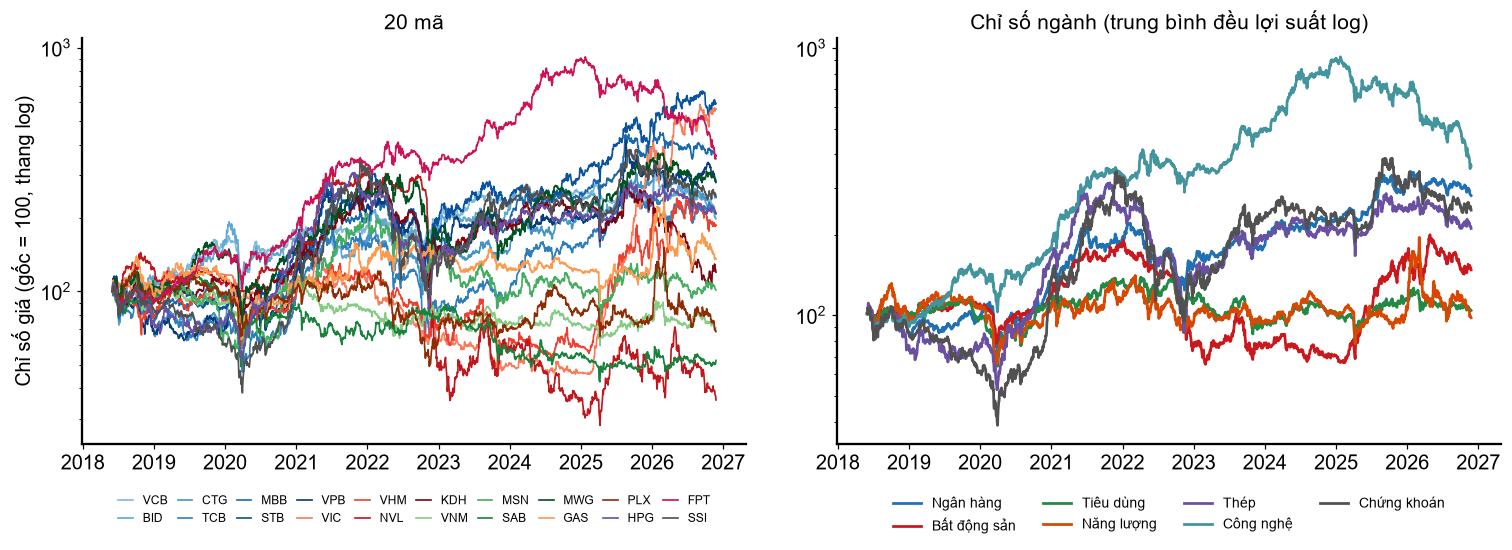

Chỉ số cuối kỳ (gốc 100) — mã:
{'VCB': 209, 'BID': 199, 'CTG': 243, 'TCB': 210, 'MBB': 351, 'STB': 590, 'VPB': 280, 'VIC': 561, 'VHM': 187, 'NVL': 36, 'KDH': 120, 'VNM': 71, 'MSN': 101, 'SAB': 52, 'MWG': 284, 'GAS': 136, 'PLX': 68, 'HPG': 208, 'FPT': 358, 'SSI': 245}
Chỉ số cuối kỳ — ngành:
{'Ngân hàng': 280, 'Bất động sản': 148, 'Tiêu dùng': 104, 'Năng lượng': 98, 'Thép': 211, 'Công nghệ': 362, 'Chứng khoán': 247}


In [2]:
px = con.execute("SELECT time, symbol, close FROM v_analysis ORDER BY time").df() \
        .pivot(index="time", columns="symbol", values="close")[SYMBOLS]
rebased = 100 * px / px.bfill().iloc[0]      # TCB thiếu 2 phiên đầu: chuẩn hoá về 100 tại phiên đầu có giá

# chỉ số ngành: trung bình đều lợi suất log các mã trong ngành, cộng dồn
r0 = con.execute("SELECT * FROM v_returns_wide").df().set_index("time")[SYMBOLS]
sector_idx = pd.DataFrame({sec: 100 * np.exp(r0[[s for s in SYMBOLS if SECTOR[s] == sec]].mean(axis=1).fillna(0).cumsum())
                           for sec in SECTORS})

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
for s in SYMBOLS:
    axes[0].plot(rebased.index, rebased[s], color=COL[s], lw=1.1, label=s)
axes[0].set_yscale("log")
axes[0].set_ylabel("Chỉ số giá (gốc = 100, thang log)")
axes[0].set_title("20 mã")
axes[0].legend(ncol=10, loc="upper center", bbox_to_anchor=(0.5, -0.1), fontsize=8, columnspacing=0.8, handlelength=1.2)
for sec in SECTORS:
    axes[1].plot(sector_idx.index, sector_idx[sec], color=(U.PALETTE["teal"] if sec == "Công nghệ" else SC[sec]), lw=1.8, label=sec)  # đổi màu Công nghệ cho khỏi trùng họ xanh lá của Tiêu dùng
axes[1].set_yscale("log")
axes[1].set_title("Chỉ số ngành (trung bình đều lợi suất log)")
axes[1].legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.1), fontsize=9)
U.finalize_figure(fig, "02_price_rebased")
plt.show()
print("Chỉ số cuối kỳ (gốc 100) — mã:"); print(rebased.iloc[-1].round(0).astype(int).to_dict())
print("Chỉ số cuối kỳ — ngành:"); print(sector_idx.iloc[-1].round(0).astype(int).to_dict())

## 2. Bảng thống kê mô tả lợi suất log ngày

In [3]:
r = con.execute("SELECT * FROM v_returns_wide").df().set_index("time")[SYMBOLS]
desc = r.describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).T
desc["skew"] = r.skew()
desc["excess_kurt"] = r.kurt()
desc["mean_ann"] = r.mean() * 252
desc["vol_ann"] = r.std() * np.sqrt(252)
desc["sharpe_ann (rf=0)"] = desc["mean_ann"] / desc["vol_ann"]
desc.insert(0, "ngành", [SECTOR[s] for s in desc.index])
U.save_table(desc, "02_return_descriptives")
desc[["ngành", "count", "mean_ann", "vol_ann", "sharpe_ann (rf=0)", "skew", "excess_kurt", "1%", "99%", "min", "max"]]

,ngành,count,mean_ann,vol_ann,sharpe_ann (rf=0),skew,excess_kurt,1%,99%,min,max
VCB,Ngân hàng,"2,120.0000",0.0940,0.2606,0.3608,-0.0298,3.3233,-0.0494,0.0483,-0.0725,0.0673
BID,Ngân hàng,"2,120.0000",0.0834,0.3341,0.2498,-0.2348,2.2289,-0.0709,0.0611,-0.0726,0.0680
CTG,Ngân hàng,"2,120.0000",0.1071,0.3283,0.3261,-0.2038,2.3440,-0.0702,0.0602,-0.0728,0.0674
TCB,Ngân hàng,"2,118.0000",0.0804,0.3254,0.2471,-0.2737,2.5731,-0.0711,0.0607,-0.0729,0.0681
MBB,Ngân hàng,"2,120.0000",0.1499,0.3025,0.4954,-0.3438,3.0861,-0.0677,0.0541,-0.0729,0.0678
STB,Ngân hàng,"2,120.0000",0.2109,0.3709,0.5687,-0.0033,1.6337,-0.0707,0.0667,-0.0725,0.0677
VPB,Ngân hàng,"2,120.0000",0.1249,0.3433,0.3638,-0.1372,2.2862,-0.0711,0.0660,-0.0727,0.0693
VIC,Bất động sản,"2,120.0000",0.2081,0.3438,0.6053,0.1986,2.9754,-0.0717,0.0672,-0.0727,0.0677
VHM,Bất động sản,"2,120.0000",0.0758,0.3579,0.2119,0.0546,2.2343,-0.0714,0.0671,-0.0727,0.0677
NVL,Bất động sản,"2,120.0000",-0.1206,0.3739,-0.3225,-0.1796,2.1195,-0.0716,0.0663,-0.0728,0.0679


In [4]:
# Đối chiếu: cùng thống kê tính bằng SQL trong DuckDB (truy vấn return_summary) và chênh lệch tối đa với pandas
sql_summary = U.query(con, "return_summary").set_index("symbol").loc[SYMBOLS]
print("Chênh lệch tuyệt đối lớn nhất (SQL − pandas):",
      {k: round(float((sql_summary[k] - desc[k]).abs().max()), 6) for k in ["mean_ann", "vol_ann", "skew", "excess_kurt"]})
sql_summary

Chênh lệch tuyệt đối lớn nhất (SQL − pandas): {'mean_ann': 0.0, 'vol_ann': 0.0, 'skew': 0.0, 'excess_kurt': 0.0}


,n,mean_ann,vol_ann,skew,excess_kurt,q01,q99,min,max
symbol,,,,,,,,,
VCB,2120,0.0940,0.2606,-0.0298,3.3233,-0.0494,0.0483,-0.0725,0.0673
BID,2120,0.0834,0.3341,-0.2348,2.2289,-0.0709,0.0611,-0.0726,0.0680
CTG,2120,0.1071,0.3283,-0.2038,2.3440,-0.0702,0.0602,-0.0728,0.0674
TCB,2118,0.0804,0.3254,-0.2737,2.5731,-0.0711,0.0607,-0.0729,0.0681
MBB,2120,0.1499,0.3025,-0.3438,3.0861,-0.0677,0.0541,-0.0729,0.0678
STB,2120,0.2109,0.3709,-0.0033,1.6337,-0.0707,0.0667,-0.0725,0.0677
VPB,2120,0.1249,0.3433,-0.1372,2.2862,-0.0711,0.0660,-0.0727,0.0693
VIC,2120,0.2081,0.3438,0.1986,2.9754,-0.0717,0.0672,-0.0727,0.0677
VHM,2120,0.0758,0.3579,0.0546,2.2343,-0.0714,0.0671,-0.0727,0.0677


## 3. Rủi ro sụt giảm (drawdown) và tỷ lệ phiên tăng/giảm

In [5]:
wealth = np.exp(r.cumsum())
drawdown = wealth / wealth.cummax() - 1
risk = pd.DataFrame({
    "ngành": [SECTOR[s] for s in SYMBOLS],
    "max_drawdown": drawdown.min(),
    "ngày đáy": drawdown.idxmin().dt.date,
    "tỷ lệ phiên tăng": (r > 0).mean(),
    "tỷ lệ phiên giảm": (r < 0).mean(),
    "tỷ lệ phiên đứng giá": (r == 0).mean(),
})
U.save_table(risk, "02_drawdown_updown")
risk

,ngành,max_drawdown,ngày đáy,tỷ lệ phiên tăng,tỷ lệ phiên giảm,tỷ lệ phiên đứng giá
VCB,Ngân hàng,-0.3949,2020-03-23,0.4632,0.4533,0.0835
BID,Ngân hàng,-0.4450,2020-03-23,0.4566,0.4759,0.0675
CTG,Ngân hàng,-0.5187,2022-10-11,0.4835,0.4557,0.0608
TCB,Ngân hàng,-0.6434,2022-11-15,0.4679,0.4557,0.0755
MBB,Ngân hàng,-0.5064,2022-11-15,0.4769,0.4377,0.0854
STB,Ngân hàng,-0.5858,2022-10-24,0.4774,0.4552,0.0675
VPB,Ngân hàng,-0.4851,2020-03-31,0.4646,0.4415,0.0939
VIC,Bất động sản,-0.6883,2025-02-12,0.4448,0.4354,0.1198
VHM,Bất động sản,-0.6099,2024-08-05,0.4505,0.4585,0.0910
NVL,Bất động sản,-0.9123,2025-04-09,0.4528,0.4505,0.0967


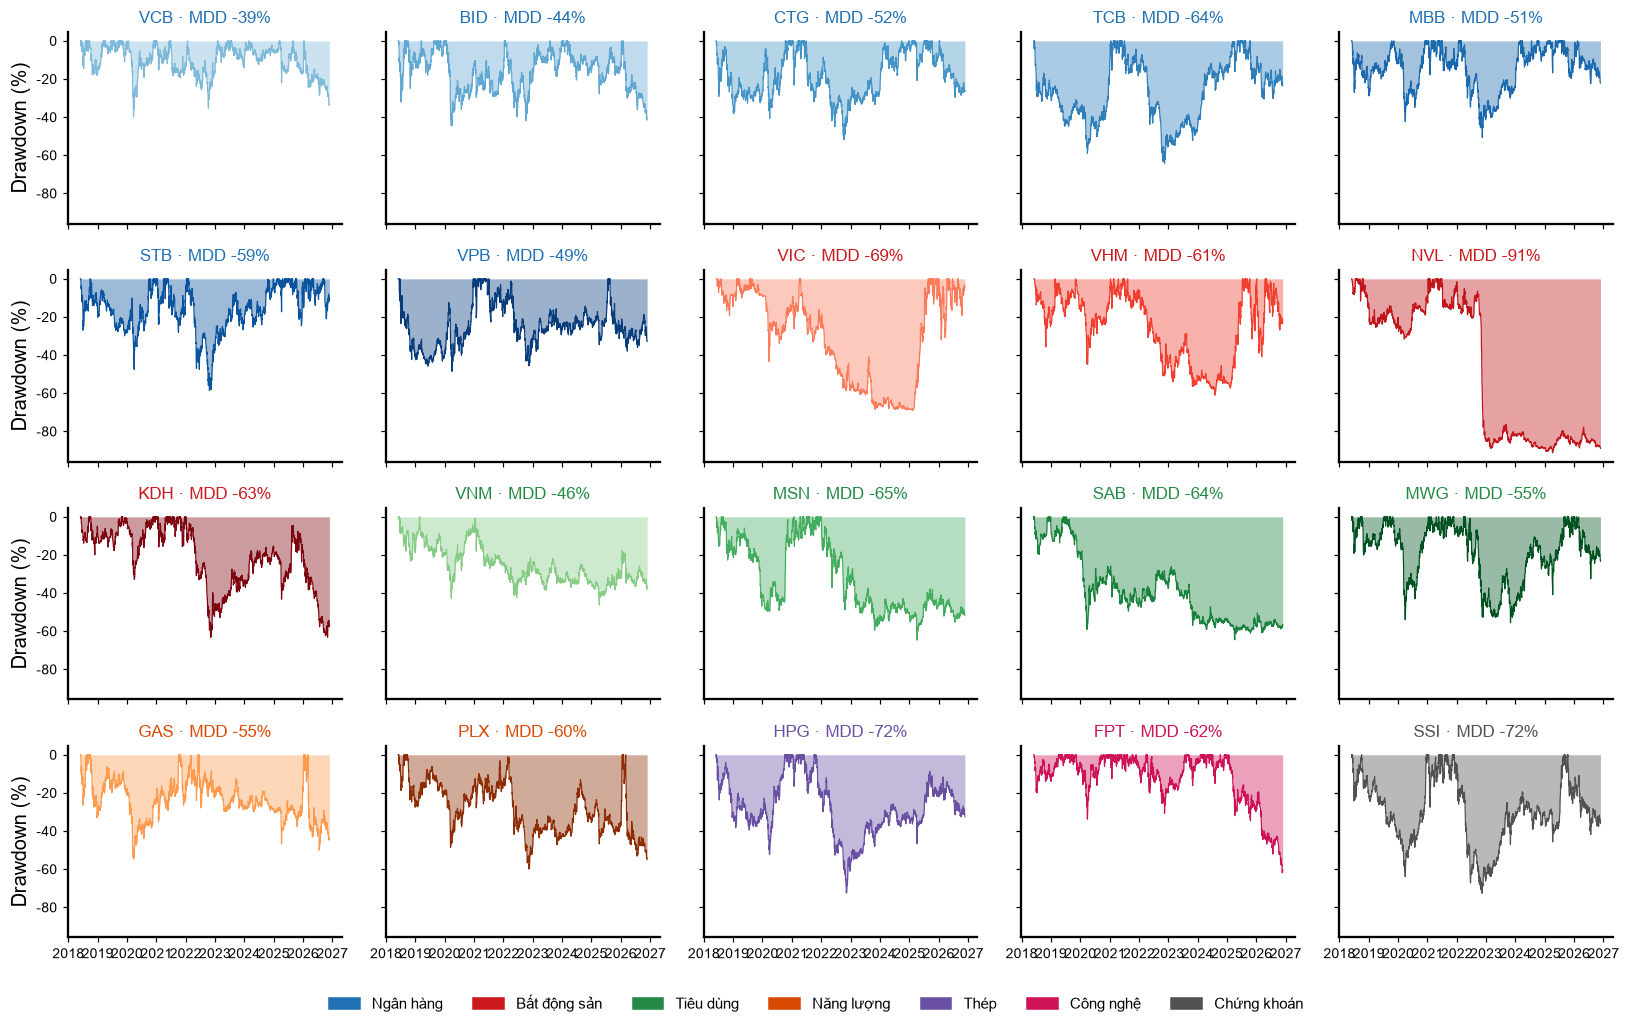

In [6]:
fig, axes = plt.subplots(4, 5, figsize=(15, 9), sharex=True, sharey=True)
for ax, s in zip(axes.ravel(), SYMBOLS):
    ax.fill_between(drawdown.index, 100 * drawdown[s], color=COL[s], alpha=0.4, lw=0)
    ax.plot(drawdown.index, 100 * drawdown[s], color=COL[s], lw=0.8)
    ax.set_title(f"{s} · MDD {100 * drawdown[s].min():.0f}%", fontsize=11, color=SC[SECTOR[s]])
    ax.tick_params(labelsize=9)
for ax in axes[:, 0]: ax.set_ylabel("Drawdown (%)")
sector_legend(fig, loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=7, fontsize=10)
U.finalize_figure(fig, "02_drawdown")
plt.show()

## 4. Lợi suất và biến động theo năm

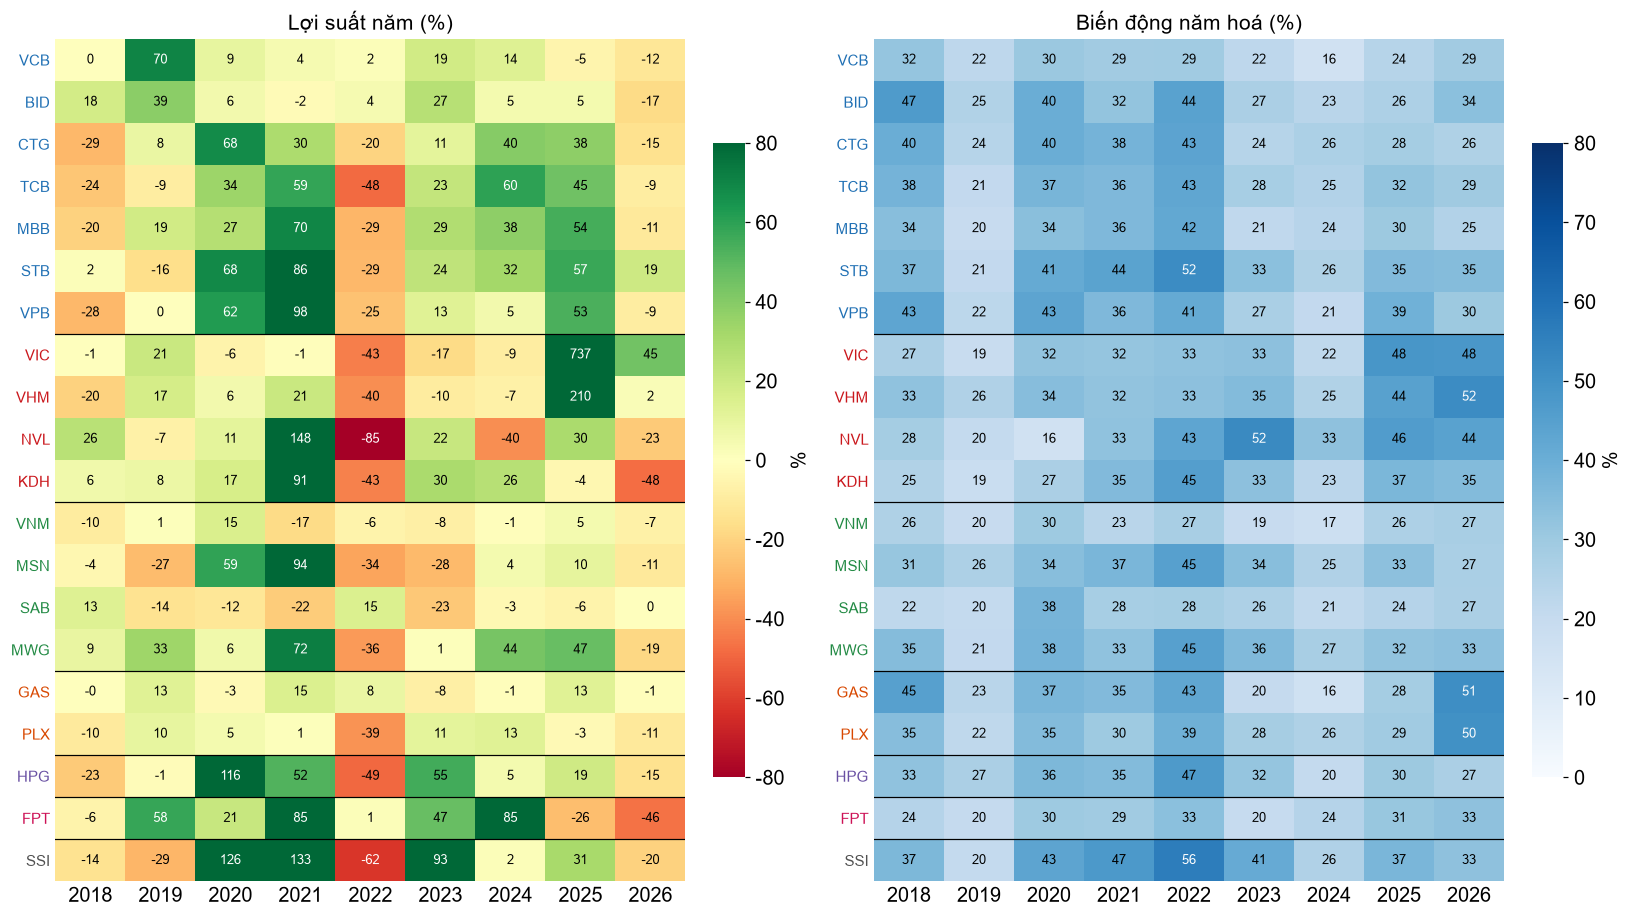

year                           2018     2019     2020     2021     2022  \
lợi suất (%)  Ngân hàng    -11.8000  15.9000  39.2000  49.2000 -20.7000   
              Bất động sản   2.8000   9.5000   6.8000  64.7000 -52.7000   
              Tiêu dùng      2.1000  -1.8000  17.1000  31.7000 -15.4000   
              Năng lượng    -5.2000  11.4000   0.8000   7.7000 -15.1000   
              Thép         -22.8000  -1.4000 115.8000  52.2000 -48.8000   
              Công nghệ     -6.1000  58.1000  21.3000  84.8000   1.3000   
              Chứng khoán  -14.1000 -29.3000 126.2000 132.8000 -62.2000   
biến động (%) Ngân hàng     38.6000  22.1000  38.2000  35.9000  42.1000   
              Bất động sản  28.2000  20.9000  27.4000  33.0000  38.6000   
              Tiêu dùng     28.4000  21.8000  34.9000  30.2000  36.4000   
              Năng lượng    39.8000  22.5000  36.1000  32.7000  40.9000   
              Thép          32.7000  26.6000  36.3000  35.3000  47.2000   
              Công nghệ     24.3000  20.1000  29.9000  29.3000  33.5000   
              Chứng khoán   36.6000  20.4000  43.3000  47.3000  56.1000   

year                           2023    2024     2025     2026  
lợi suất (%)  Ngân hàng     20.7000 27.5000  35.4000  -7.7000  
              Bất động sản   6.2000 -7.5000 243.3000  -5.9000  
              Tiêu dùng    -14.5000 11.0000  13.9000  -9.1000  
              Năng lượng     1.6000  6.0000   5.1000  -6.2000  
              Thép          55.3000  4.9000  18.9000 -14.9000  
              Công nghệ     47.1000 85.0000 -26.4000 -46.4000  
              Chứng khoán   92.6000  1.8000  30.7000 -20.2000  
biến động (%) Ngân hàng     26.0000 22.9000  30.6000  29.7000  
              Bất động sản  38.5000 25.7000  43.9000  44.9000  
              Tiêu dùng     28.9000 22.8000  28.9000  28.6000  
              Năng lượng    24.1000 21.0000  28.7000  50.5000  
              Thép          31.8000 20.4000  30.1000  26.8000  
              Công nghệ     19.9000 24.1000  31.0000  32.9000  
              Chứng khoán   41.2000 25.5000  36.9000  33.0000

In [7]:
# Tính trực tiếp trên khung phân tích chung (2018 chỉ từ 01/06, 2026 đến 25/11) để khớp mọi phân tích khác
rl = r.copy(); rl["year"] = rl.index.year
ret_y = np.exp(rl.groupby("year")[SYMBOLS].sum()).T - 1
vol_y = (rl.groupby("year")[SYMBOLS].std() * np.sqrt(252)).T
U.save_table(100 * ret_y, "02_yearly_return_pct"); U.save_table(100 * vol_y, "02_yearly_vol_pct")

fig, axes = plt.subplots(1, 2, figsize=(15, 8.5))
for ax, M, kw in [(axes[0], 100 * ret_y, dict(cmap="RdYlGn", vmin=-80, vmax=80, title="Lợi suất năm (%)")),
                  (axes[1], 100 * vol_y, dict(cmap="Blues", vmin=0, vmax=80, title="Biến động năm hoá (%)"))]:
    U.make_heatmap(ax, M, fmt="{:.0f}", cbar_label="%", **kw)
    for t in ax.texts: t.set_fontsize(8.5)
    ax.set_yticks(range(len(SYMBOLS)), SYMBOLS, fontsize=10)
    for t, s in zip(ax.get_yticklabels(), SYMBOLS): t.set_color(SC[SECTOR[s]])
    for i in range(1, len(SYMBOLS)):
        if SECTOR[SYMBOLS[i]] != SECTOR[SYMBOLS[i - 1]]: ax.axhline(i - 0.5, color="black", lw=0.8)
U.finalize_figure(fig, "02_yearly_heatmap")
plt.show()

# trung bình theo ngành: lợi suất năm và biến động năm (trung bình đều các mã trong ngành)
sec_y = pd.concat({"lợi suất (%)": 100 * ret_y.groupby(lambda s: SECTOR[s], sort=False).mean(),
                   "biến động (%)": 100 * vol_y.groupby(lambda s: SECTOR[s], sort=False).mean()})
sec_y.round(1)

## 5. Biến động lịch sử 20 phiên (năm hoá)

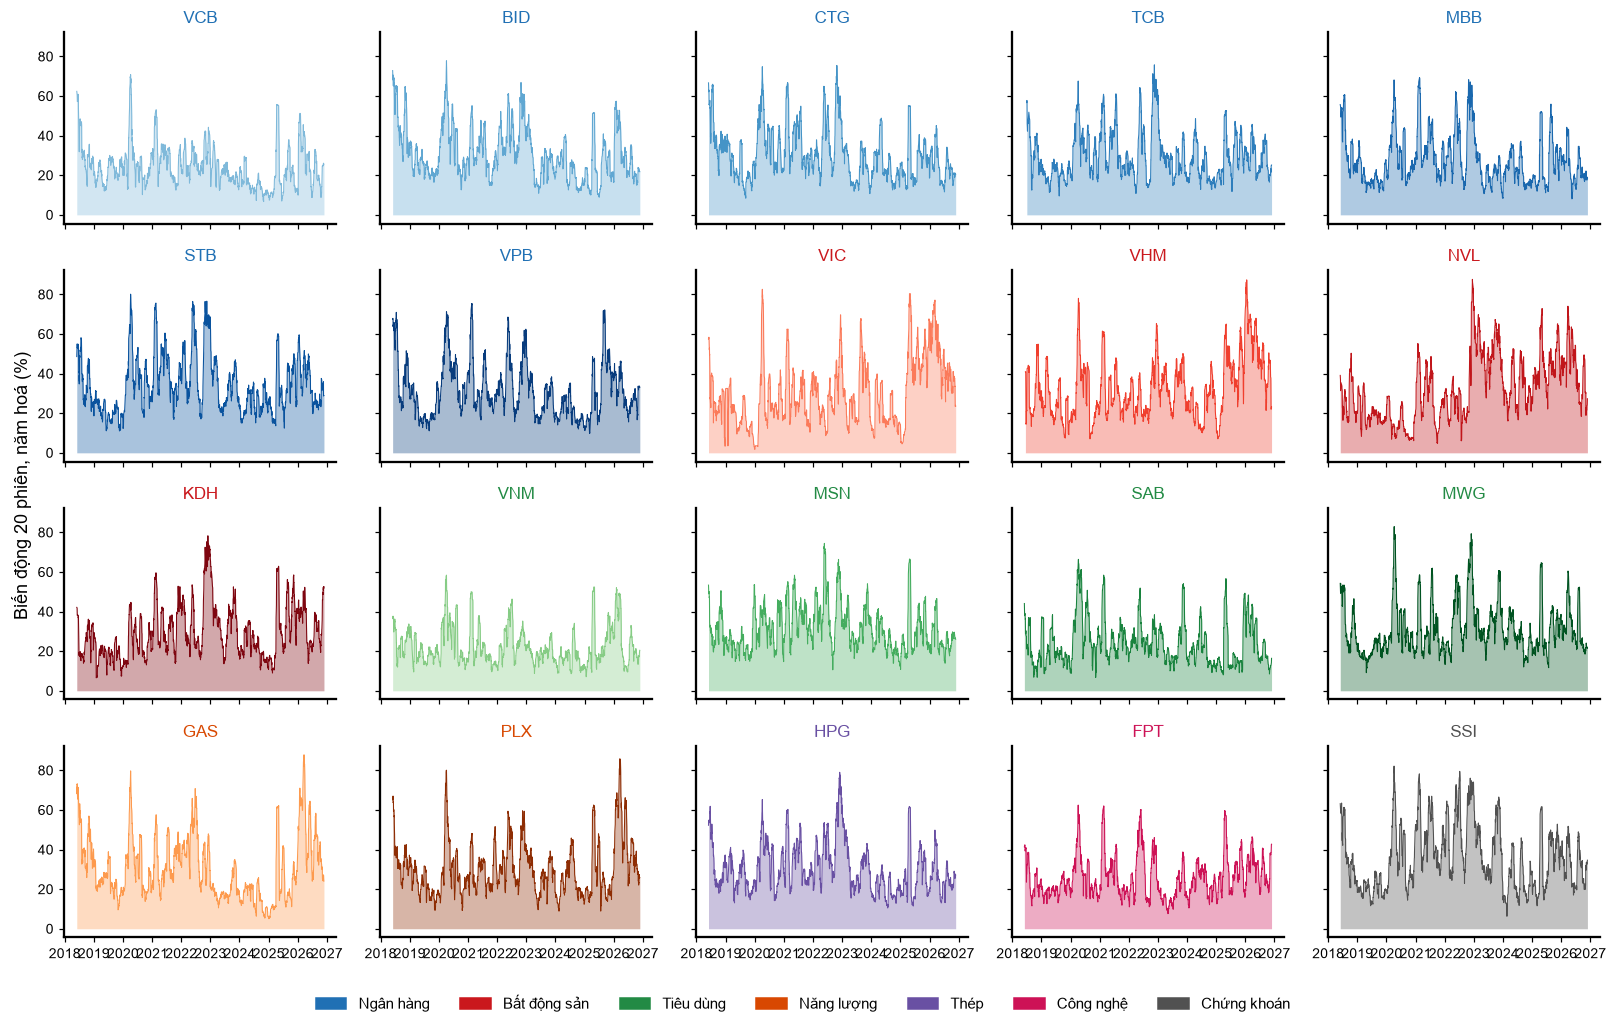

Biến động 20 phiên trung bình 20 mã: đỉnh 67% ngày 06/04/2020; thấp nhất 15% ngày 03/01/2025
Trung bình theo năm (%): {2018: 34.1, 2019: 21.4, 2020: 31.7, 2021: 32.4, 2022: 37.0, 2023: 29.2, 2024: 22.3, 2025: 29.8, 2026: 33.3}


In [8]:
vol = con.execute("SELECT time, symbol, vol_20d * SQRT(252) AS v FROM v_analysis").df() \
         .pivot(index="time", columns="symbol", values="v")[SYMBOLS]

fig, axes = plt.subplots(4, 5, figsize=(15, 9), sharex=True, sharey=True)
for ax, s in zip(axes.ravel(), SYMBOLS):
    ax.fill_between(vol.index, 100 * vol[s], color=COL[s], alpha=0.35, lw=0)
    ax.plot(vol.index, 100 * vol[s], color=COL[s], lw=0.7)
    ax.set_title(s, fontsize=11, color=SC[SECTOR[s]])
    ax.tick_params(labelsize=9)
fig.supylabel("Biến động 20 phiên, năm hoá (%)", fontsize=12)
sector_legend(fig, loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=7, fontsize=10)
U.finalize_figure(fig, "02_rolling_volatility")
plt.show()
mv = vol.mean(axis=1)
print(f"Biến động 20 phiên trung bình 20 mã: đỉnh {100*mv.max():.0f}% ngày {mv.idxmax():%d/%m/%Y}; thấp nhất {100*mv.min():.0f}% ngày {mv.idxmin():%d/%m/%Y}")
print("Trung bình theo năm (%):", (100 * mv.groupby(mv.index.year).mean()).round(1).to_dict())

## 6. Phân bố lợi suất theo mã (boxplot) và thanh khoản

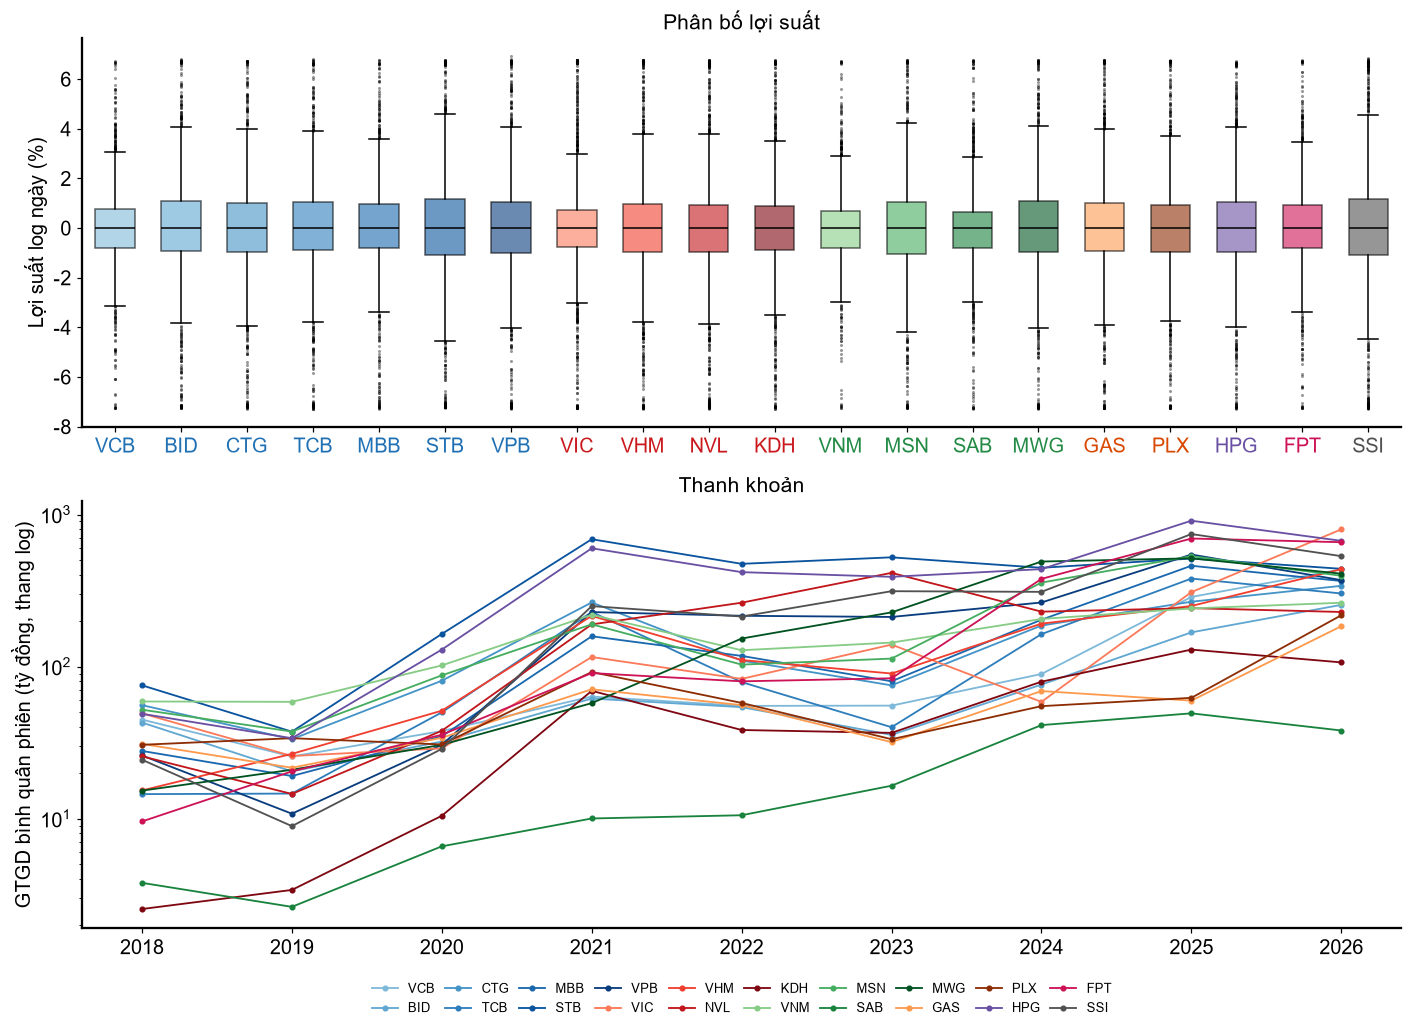

year,ngành,2018,2019,2020,2021,2022,2023,2024,2025,2026
symbol,,,,,,,,,,
VCB,Ngân hàng,45.0000,26.0000,38.0000,64.0000,55.0000,55.0000,89.0000,287.0000,435.0000
BID,Ngân hàng,43.0000,20.0000,32.0000,62.0000,54.0000,36.0000,76.0000,168.0000,255.0000
CTG,Ngân hàng,56.0000,33.0000,81.0000,264.0000,110.0000,75.0000,186.0000,267.0000,340.0000
TCB,Ngân hàng,14.0000,15.0000,50.0000,229.0000,79.0000,40.0000,164.0000,379.0000,303.0000
MBB,Ngân hàng,28.0000,19.0000,35.0000,158.0000,118.0000,80.0000,203.0000,460.0000,365.0000
STB,Ngân hàng,75.0000,37.0000,164.0000,688.0000,474.0000,523.0000,446.0000,514.0000,440.0000
VPB,Ngân hàng,26.0000,11.0000,31.0000,228.0000,216.0000,212.0000,264.0000,546.0000,370.0000
VIC,Bất động sản,49.0000,26.0000,29.0000,116.0000,83.0000,140.0000,59.0000,309.0000,799.0000
VHM,Bất động sản,15.0000,27.0000,51.0000,215.0000,110.0000,90.0000,192.0000,250.0000,437.0000


In [9]:
liq = con.execute("""
    SELECT symbol, YEAR(time) AS year, SUM(trade_value) / 1e6 / COUNT(*) AS gtgd_ty
    FROM v_analysis GROUP BY ALL ORDER BY year""").df() \
    .pivot(index="year", columns="symbol", values="gtgd_ty")[SYMBOLS]

fig, axes = plt.subplots(2, 1, figsize=(13, 9.5), gridspec_kw={"height_ratios": [1, 1.1]})
bp = axes[0].boxplot([100 * r[s].dropna() for s in SYMBOLS], tick_labels=SYMBOLS, patch_artist=True,
                     widths=0.6, flierprops=dict(marker=".", markersize=2, alpha=0.4),
                     medianprops=dict(color="black"))
for patch, s in zip(bp["boxes"], SYMBOLS):
    patch.set_facecolor(COL[s]); patch.set_alpha(0.6)
for t, s in zip(axes[0].get_xticklabels(), SYMBOLS): t.set_color(SC[SECTOR[s]])
axes[0].set_ylabel("Lợi suất log ngày (%)")
axes[0].set_title("Phân bố lợi suất")
for s in SYMBOLS:
    axes[1].plot(liq.index, liq[s], marker="o", ms=3, color=COL[s], lw=1.2, label=s)
axes[1].set_yscale("log")
axes[1].set_ylabel("GTGD bình quân phiên (tỷ đồng, thang log)")
axes[1].set_title("Thanh khoản")
axes[1].legend(ncol=10, fontsize=8.5, loc="upper center", bbox_to_anchor=(0.5, -0.1), columnspacing=0.8)
U.finalize_figure(fig, "02_box_liquidity")
plt.show()
U.save_table(liq.T, "02_liquidity_by_year")
liq_t = liq.T.round(0); liq_t.insert(0, "ngành", [SECTOR[s] for s in liq_t.index]); liq_t

## 7. Nhận xét

(Số liệu khung 01/06/2018 – 25/11/2026: 2.120 phiên mỗi mã, 2.118 phiên đối với TCB; 2.118 phiên chung khi cần ma trận đủ 20 mã.)

- **Lợi suất – rủi ro:** lợi suất log năm hoá cao nhất ở FPT (~15,3%), STB (~21,1%) và VIC (~20,8%) (Sharpe lần lượt 0,55 / 0,57 / 0,61);
  âm ở NVL (−12,1%), SAB (−7,5%), PLX (−4,4%), VNM (−3,8%). Biến động năm hoá nằm trong khoảng 24–39%: thấp nhất VNM (24,2%) và VCB (26,1%),
  cao nhất SSI (39,5%) và NVL (37,4%). Trung bình theo ngành: ngân hàng +12,2%/năm, công nghệ +15,3%, chứng khoán +10,8%, thép +8,9%,
  bất động sản +4,6%, tiêu dùng +0,5%, năng lượng −0,3% — chênh lệch lợi suất giữa các ngành lớn hơn nhiều so với chênh lệch biến động (28–40%).
- **Năm mã gốc so với 15 mã mới:** trung bình biến động của nhóm gốc (35,5%) cao hơn nhóm mới (31,6%); MDD trung bình −66% so với −58%; lợi suất trung bình
  tương đương (7,6% so với 6,8%). Nhóm mới (nhiều mã vốn hoá lớn, ổn định như VCB, VNM, SAB, FPT) có biến động thấp hơn nhưng độ nhọn cao hơn (xem bên dưới).
- **Sụt giảm:** NVL có max drawdown −91,2% (đáy 09/04/2025); tiếp theo SSI (−72,5%) và HPG (−72,4%, cùng đáy 10/11/2022), VIC (−68,8%).
  Nhẹ nhất là VCB (−39,5%) và BID (−44,5%), cả hai đáy ngày 23/03/2020 (đợt sập COVID). Nhiều mã chạm đáy trong cùng các đợt
  (23/03/2020, 10–15/11/2022, 08–09/04/2025) → bằng chứng sơ bộ của nhân tố thị trường chung. Riêng FPT có đáy sụt giảm ở ngày 20/11/2026, tức là đang trong một đợt giảm mạnh ở cuối mẫu.
- **Theo năm:** 2021 là năm tăng mạnh ở hầu hết các ngành (chứng khoán +133%, công nghệ +85%, bất động sản +65%); 2022 là năm sập (chứng khoán −62%, bất động sản −53%, thép −49%, ngân hàng −21%);
  2025 bất động sản tăng rất mạnh (trung bình +243%, do VIC kéo), trong khi 2026 (đến 25/11) công nghệ giảm −46%. Biến động trung bình 20 phiên của 20 mã đạt đỉnh
  67% ngày 06/04/2020 (COVID), thấp nhất 15% ngày 03/01/2025; trung bình năm: 21% (2019), 37% (2022) — các đợt biến động cao trùng nhau giữa các mã.
- **Hình dạng:** trung vị lợi suất ngày bằng 0; 5,6–12,5% số phiên đứng giá (cao nhất KDH 12,5%, VIC 12,0%); độ nhọn vượt chuẩn từ 1,5 (SSI) đến 3,9 (SAB, VNM) > 0 → đuôi dày hơn
  phân phối chuẩn ở cả 20 mã; độ lệch gần 0 (−0,34 đến +0,20, hơi âm ở nhóm ngân hàng). VNM, SAB, VCB, MBB (kurtosis 3,1–3,9) có biên độ ±7% hiếm khi bị chạm nhưng thỉnh thoảng có cú sốc lớn so với mức biến động thường ngày.
- **Thanh khoản:** khác biệt rất lớn: năm 2025 GTGD bình quân phiên từ ~49 tỷ (SAB) tới ~911 tỷ (HPG); 2026 cao nhất VIC (~799 tỷ). SAB, KDH, GAS, PLX có thanh khoản thấp
  (KDH, VIC có nhiều phiên đứng giá nhất, xem trên); nhóm STB, HPG, MWG, SSI, FPT, VPB giao dịch sôi động nhất.
- **Biến động thay đổi theo thời gian:** biến động trượt dao động mạnh theo cụm (xem lưới 4×5) → gợi ý mô hình hoá biến động có điều kiện (GARCH).